Loaded UCI Wine dataset via scikit-learn.
Feature matrix shape: (178, 13)

Number of components retained to explain >= 80% variance: 5
Total variance explained: 80.16%

Principal Component Individual Variance Explained Cumulative Variance Explained
                PC1                        36.20%                        36.20%
                PC2                        19.21%                        55.41%
                PC3                        11.12%                        66.53%
                PC4                         7.07%                        73.60%
                PC5                         6.56%                        80.16%

Feature Loadings:
                                PC1    PC2    PC3    PC4    PC5
alcohol                       0.144  0.484 -0.207 -0.018 -0.266
malic_acid                   -0.245  0.225  0.089  0.537  0.035
ash                          -0.002  0.316  0.626 -0.214 -0.143
alcalinity_of_ash            -0.239 -0.011  0.612  0.061  0.066
magnesium   

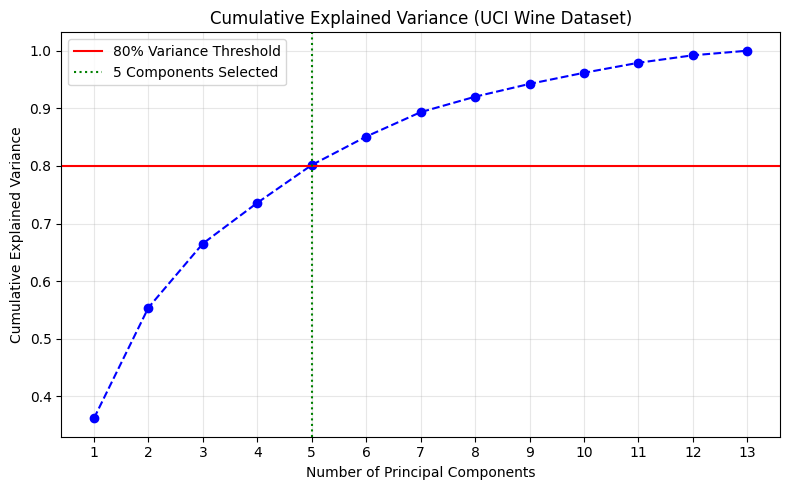

K-Means Evaluation Summary (on 5 Principal Components):
 k  Inertia (WCSS)  Silhouette Score  Calinski-Harabasz Index
 3          825.02            0.3691                   109.23
 4          723.94            0.3256                    90.61
 5          661.43            0.3078                    78.04
 6          605.38            0.2728                    71.01
 7          558.11            0.2756                    66.22
 8          516.24            0.2447                    62.98
 9          474.11            0.2240                    61.53
10          446.19            0.2212                    58.94
11          422.38            0.2196                    56.64
12          397.37            0.2193                    55.35


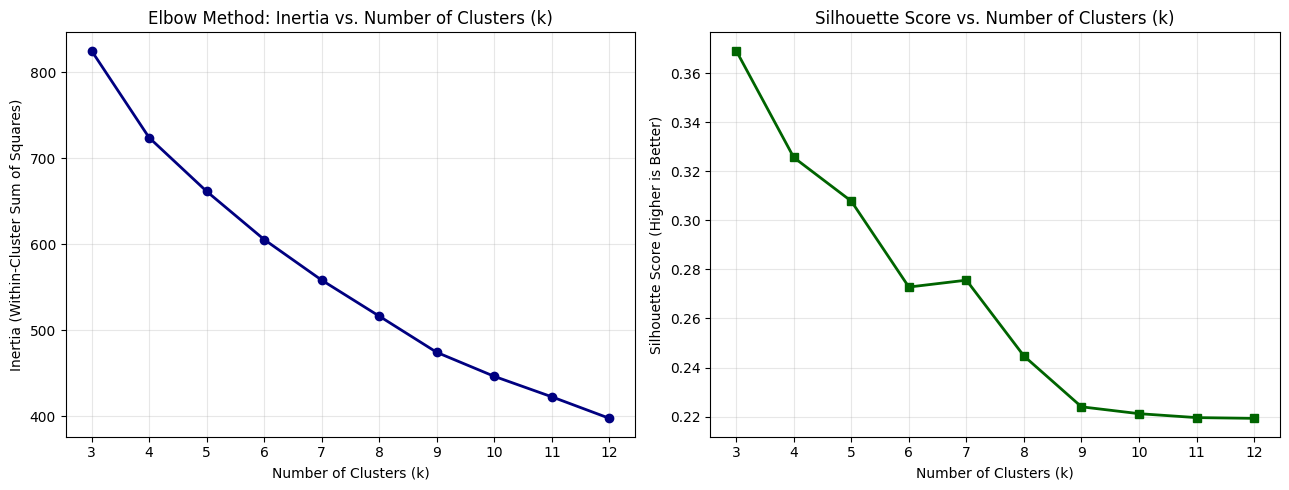

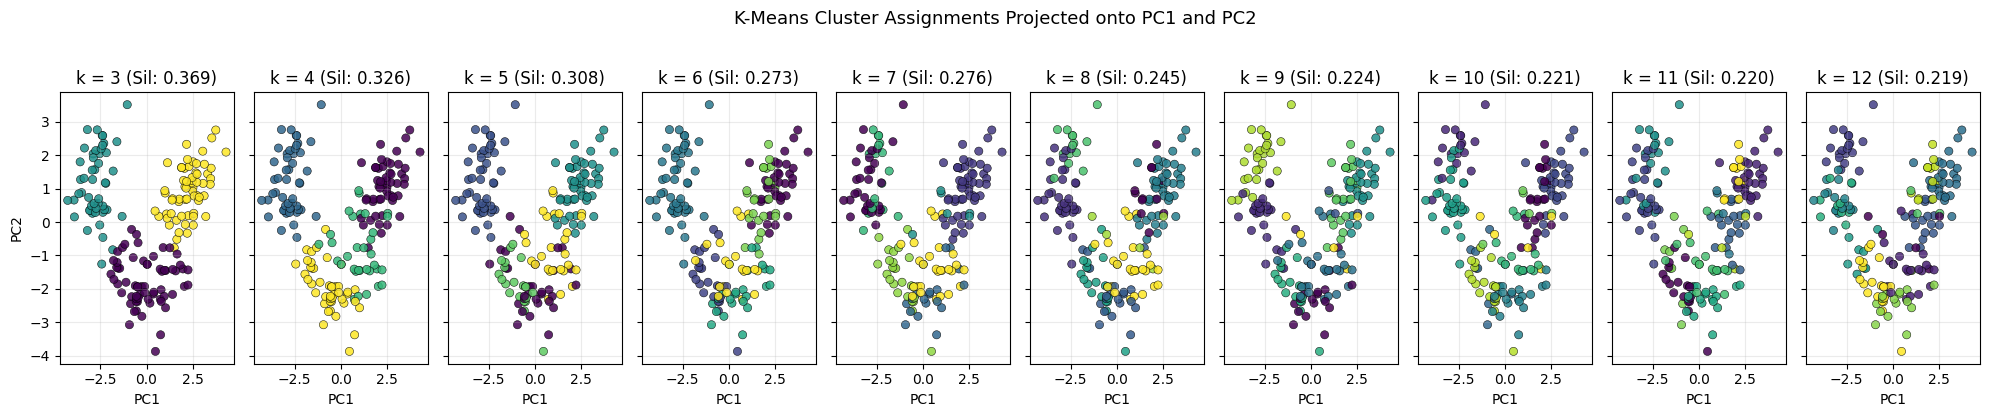

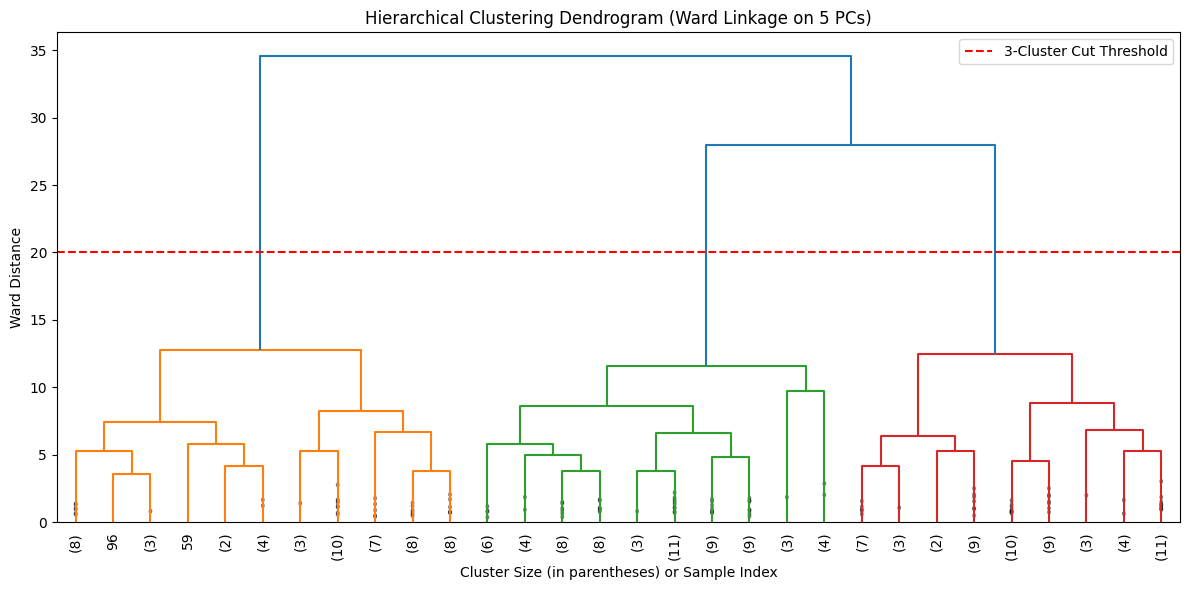

Hierarchical Clustering Evaluation Summary (on 5 Principal Components):
 k Linkage  Silhouette Score  Calinski-Harabasz Index
 3    ward            0.3468                   100.02
 4    ward            0.2913                    79.22
 5    ward            0.2679                    70.37
 6    ward            0.2812                    65.42
 7    ward            0.2859                    60.80


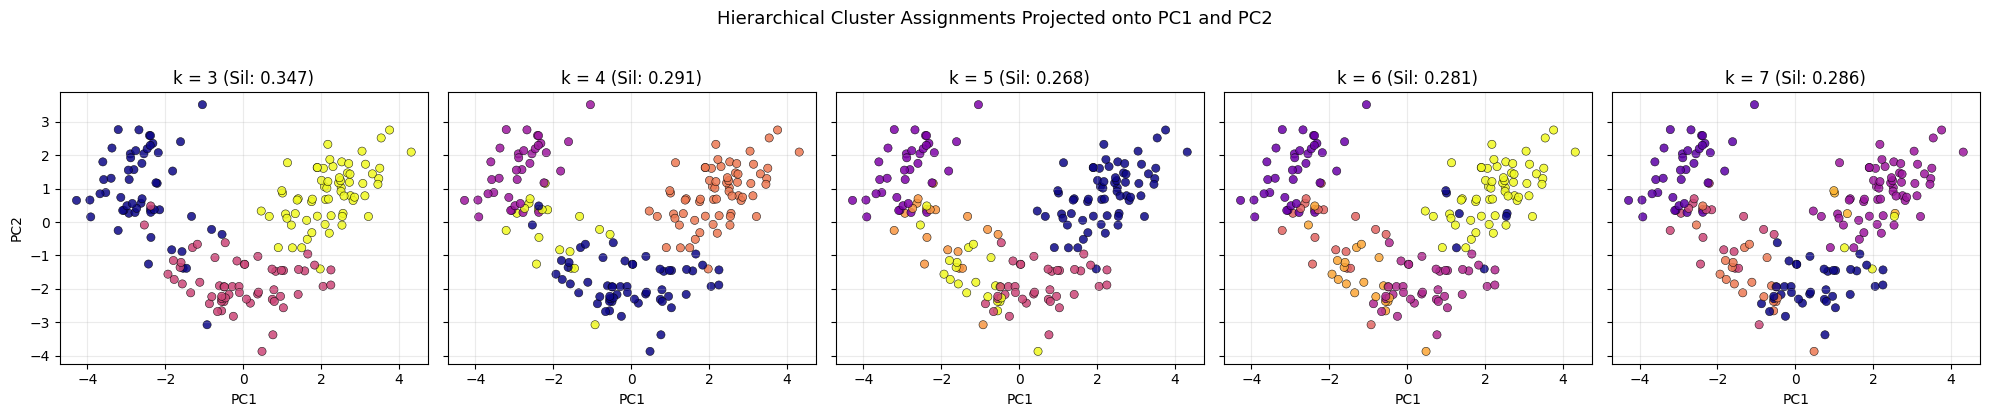

=== 1. PCA FACTORABILITY DIAGNOSTICS ===
Bartlett's Test Chi-Square: 1317.18 (df=78), p-value: 2.4686e-224
-> Passed: Variables are significantly correlated (suitable for PCA).
Overall KMO Score: 0.7787 (Target > 0.60; > 0.70 is good)

=== 2. MULTIVARIATE OUTLIER CHECK (MAHALANOBIS DISTANCE) ===
Critical Squared Mahalanobis Threshold (p < 0.001, df=5): 20.52
Number of extreme multivariate outliers detected: 1
Outlier row indices: [69]

=== 3. CLUSTER SIZE BALANCE (k = 3) ===
                    True Cultivar Counts  K-Means (k=3) Counts  \
Group A (Largest)                     59                    65   
Group B (Middle)                      71                    62   
Group C (Smallest)                    48                    51   

                    Ward Hierarchical (k=3) Counts  
Group A (Largest)                               65  
Group B (Middle)                                58  
Group C (Smallest)                              55  

=== 4. CLUSTER STABILITY & GROUND-TRUTH AG

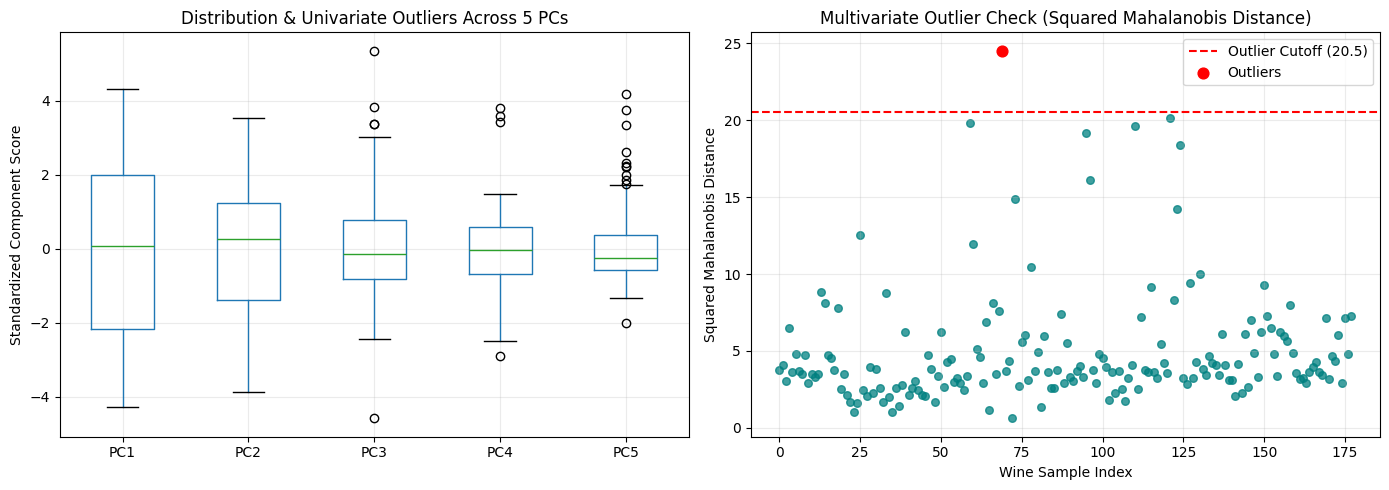

In [1]:
# A. Conduct PCA to collapse correlated variables into a subset that includes 80% of the variance of the entirety of the data. 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine

# 1. Load the UCI Wine dataset directly (no local file needed)
column_names = [
    'class', 'Alcohol', 'Malic_acid', 'Ash', 'Alcalinity_of_ash',
    'Magnesium', 'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
    'Proanthocyanins', 'Color_intensity', 'Hue',
    'OD280_OD315_of_diluted_wines', 'Proline'
]

uci_url = "https://uci.edu"

try:
    df = pd.read_csv(uci_url, header=None, names=column_names)
    X = df.drop(columns=['class'])
    y = df['class']
    print("Successfully loaded dataset directly from UCI repository.")
except Exception:
    # Offline fallback: sklearn's load_wine() is the exact same UCI dataset
    wine = load_wine(as_frame=True)
    X = wine.data
    y = wine.target
    print("Loaded UCI Wine dataset via scikit-learn.")

print(f"Feature matrix shape: {X.shape}")

# 2. Standardize the 13 continuous features (Mean = 0, Variance = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply PCA retaining at least 80% of the total variance
pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pc_columns = [f'PC{i+1}' for i in range(pca.n_components_)]
df_pca = pd.DataFrame(X_pca, columns=pc_columns)

# 4. Inspect Variance Explained
explained_var = pca.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

print(f"\nNumber of components retained to explain >= 80% variance: {pca.n_components_}")
print(f"Total variance explained: {cumulative_var[-1]:.2%}\n")

summary_df = pd.DataFrame({
    'Principal Component': pc_columns,
    'Individual Variance Explained': [f"{v:.2%}" for v in explained_var],
    'Cumulative Variance Explained': [f"{c:.2%}" for c in cumulative_var]
})
print(summary_df.to_string(index=False))

# 5. Inspect Feature Loadings (how original variables map to each component)
loadings = pd.DataFrame(
    pca.components_.T,
    columns=pc_columns,
    index=X.columns
)
print("\nFeature Loadings:")
print(loadings.round(3))

# 6. Visualize Cumulative Explained Variance across all 13 components
pca_full = PCA().fit(X_scaled)
cum_var_full = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var_full) + 1), cum_var_full, marker='o', linestyle='--', color='b')
plt.axhline(y=0.80, color='r', linestyle='-', label='80% Variance Threshold')
plt.axvline(x=pca.n_components_, color='g', linestyle=':', label=f'{pca.n_components_} Components Selected')
plt.title('Cumulative Explained Variance (UCI Wine Dataset)')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.xticks(range(1, len(cum_var_full) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# B. k-means to identify clusters, 

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score


try:
    df = pd.read_csv(uci_url, header=None, names=column_names)
    X = df.drop(columns=['class'])
    y = df['class']
except Exception:
    wine = load_wine(as_frame=True)
    X = wine.data
    y = wine.target

# 2. Standardize and apply PCA (80% variance threshold -> 5 components)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pc_columns = [f'PC{i+1}' for i in range(pca.n_components_)]
df_pca = pd.DataFrame(X_pca, columns=pc_columns)

# 3. Evaluate K-Means across k = 3 to 13
k_values = range(3, 13)
results = []
cluster_assignments = {}

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(df_pca)
    
    inertia = kmeans.inertia_
    sil_score = silhouette_score(df_pca, labels)
    ch_score = calinski_harabasz_score(df_pca, labels)
    
    results.append({
        'k': k,
        'Inertia (WCSS)': round(inertia, 2),
        'Silhouette Score': round(sil_score, 4),
        'Calinski-Harabasz Index': round(ch_score, 2)
    })
    cluster_assignments[k] = labels

results_df = pd.DataFrame(results)
print("K-Means Evaluation Summary (on 5 Principal Components):")
print(results_df.to_string(index=False))

# 4. Plot Elbow Curve (Inertia) and Silhouette Scores
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow Plot
axes[0].plot(results_df['k'], results_df['Inertia (WCSS)'], marker='o', color='navy', linewidth=2)
axes[0].set_title('Elbow Method: Inertia vs. Number of Clusters (k)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].set_xticks(k_values)
axes[0].grid(True, alpha=0.3)

# Silhouette Plot
axes[1].plot(results_df['k'], results_df['Silhouette Score'], marker='s', color='darkgreen', linewidth=2)
axes[1].set_title('Silhouette Score vs. Number of Clusters (k)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score (Higher is Better)')
axes[1].set_xticks(k_values)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. Visualize the clusters in PC1 vs. PC2 space for all tested k values
fig, axes = plt.subplots(1, len(k_values), figsize=(20, 4), sharey=True)

for idx, k in enumerate(k_values):
    axes[idx].scatter(
        df_pca['PC1'], df_pca['PC2'],
        c=cluster_assignments[k], cmap='viridis', s=35, alpha=0.85, edgecolor='k', linewidth=0.4
    )
    axes[idx].set_title(f'k = {k} (Sil: {results_df.loc[idx, "Silhouette Score"]:.3f})')
    axes[idx].set_xlabel('PC1')
    if idx == 0:
        axes[idx].set_ylabel('PC2')
    axes[idx].grid(True, alpha=0.25)

plt.suptitle('K-Means Cluster Assignments Projected onto PC1 and PC2', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

# Note: k=3 is the top choice due to highest Silhouette Score and Calinski-Harabasz Index

# C. hierarchical clustering

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load the UCI Wine dataset
column_names = [
    'class', 'Alcohol', 'Malic_acid', 'Ash', 'Alcalinity_of_ash',
    'Magnesium', 'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
    'Proanthocyanins', 'Color_intensity', 'Hue',
    'OD280_OD315_of_diluted_wines', 'Proline'
]
uci_url = "https://uci.edu"

try:
    df = pd.read_csv(uci_url, header=None, names=column_names)
    X = df.drop(columns=['class'])
    y = df['class']
except Exception:
    wine = load_wine(as_frame=True)
    X = wine.data
    y = wine.target

# 2. Standardize and apply PCA (80% variance threshold -> 5 components)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pc_columns = [f'PC{i+1}' for i in range(pca.n_components_)]
df_pca = pd.DataFrame(X_pca, columns=pc_columns)

# 3. Compute the Ward linkage matrix and plot the Dendrogram
Z = linkage(df_pca, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    truncate_mode='lastp',  # Show the top 30 merged clusters for readability
    p=30,
    leaf_rotation=90.,
    leaf_font_size=10.,
    show_contracted=True
)
plt.axhline(y=20, color='r', linestyle='--', label='3-Cluster Cut Threshold')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage on 5 PCs)')
plt.xlabel('Cluster Size (in parentheses) or Sample Index')
plt.ylabel('Ward Distance')
plt.legend()
plt.tight_layout()
plt.show()

# 4. Evaluate Agglomerative Clustering across k = 3, 4, 5, 6, 7
k_values = list(range(3, 8))
results = []
hc_assignments = {}

for k in k_values:
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = hc.fit_predict(df_pca)
    
    sil_score = silhouette_score(df_pca, labels)
    ch_score = calinski_harabasz_score(df_pca, labels)
    
    results.append({
        'k': k,
        'Linkage': 'ward',
        'Silhouette Score': round(sil_score, 4),
        'Calinski-Harabasz Index': round(ch_score, 2)
    })
    hc_assignments[k] = labels

results_df = pd.DataFrame(results)
print("Hierarchical Clustering Evaluation Summary (on 5 Principal Components):")
print(results_df.to_string(index=False))

# 5. Visualize Hierarchical Clusters in PC1 vs. PC2 space for all tested k values
fig, axes = plt.subplots(1, len(k_values), figsize=(20, 4), sharey=True)

for idx, k in enumerate(k_values):
    axes[idx].scatter(
        df_pca['PC1'], df_pca['PC2'],
        c=hc_assignments[k], cmap='plasma', s=35, alpha=0.85, edgecolor='k', linewidth=0.4
    )
    axes[idx].set_title(f'k = {k} (Sil: {results_df.loc[idx, "Silhouette Score"]:.3f})')
    axes[idx].set_xlabel('PC1')
    if idx == 0:
        axes[idx].set_ylabel('PC2')
    axes[idx].grid(True, alpha=0.25)

plt.suptitle('Hierarchical Cluster Assignments Projected onto PC1 and PC2', y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

# D. investigate assumptions

from scipy import stats
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Load & Standardize the UCI Wine dataset, then run PCA (80% variance)
column_names = [
    'class', 'Alcohol', 'Malic_acid', 'Ash', 'Alcalinity_of_ash',
    'Magnesium', 'Total_phenols', 'Flavanoids', 'Nonflavanoid_phenols',
    'Proanthocyanins', 'Color_intensity', 'Hue',
    'OD280_OD315_of_diluted_wines', 'Proline'
]
uci_url = "https://uci.edu"

try:
    df = pd.read_csv(uci_url, header=None, names=column_names)
    X = df.drop(columns=['class'])
    y = df['class']
except Exception:
    wine = load_wine(as_frame=True)
    X = wine.data
    y = wine.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.80, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pc_columns = [f'PC{i+1}' for i in range(pca.n_components_)]
df_pca = pd.DataFrame(X_pca, columns=pc_columns)

# ==============================================================================
# DIAGNOSTIC 1: Correlation Structure, Bartlett's Test & KMO (PCA Factorability)
# ==============================================================================
print("=== 1. PCA FACTORABILITY DIAGNOSTICS ===")
n_samples, n_features = X_scaled.shape
corr_matrix = np.corrcoef(X_scaled, rowvar=False)

# Bartlett's Test of Sphericity
det_corr = np.linalg.det(corr_matrix)
chi_square = -((n_samples - 1) - (2 * n_features + 5) / 6) * np.log(det_corr)
dof = n_features * (n_features - 1) / 2
p_value = stats.chi2.sf(chi_square, dof)

print(f"Bartlett's Test Chi-Square: {chi_square:.2f} (df={int(dof)}), p-value: {p_value:.4e}")
if p_value < 0.05:
    print("-> Passed: Variables are significantly correlated (suitable for PCA).")
else:
    print("-> Warning: Variables may be uncorrelated.")

# Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy
inv_corr = np.linalg.inv(corr_matrix)
# Partial correlation matrix
diag_inv = np.sqrt(np.diag(inv_corr))
partial_corr = -inv_corr / np.outer(diag_inv, diag_inv)
np.fill_diagonal(partial_corr, 0)

corr_sq_sum = np.sum(corr_matrix**2) - n_features  # exclude diagonal 1s
part_sq_sum = np.sum(partial_corr**2)
kmo_overall = corr_sq_sum / (corr_sq_sum + part_sq_sum)

print(f"Overall KMO Score: {kmo_overall:.4f} (Target > 0.60; > 0.70 is good)\n")

# ==============================================================================
# DIAGNOSTIC 2: Multivariate Outlier Detection (Mahalanobis Distance on 5 PCs)
# ==============================================================================
print("=== 2. MULTIVARIATE OUTLIER CHECK (MAHALANOBIS DISTANCE) ===")
cov_pca = np.cov(X_pca, rowvar=False)
inv_cov_pca = np.linalg.inv(cov_pca)
mean_pca = np.mean(X_pca, axis=0)

diff = X_pca - mean_pca
mahal_sq = np.sum((diff @ inv_cov_pca) * diff, axis=1)
mahal_dist = np.sqrt(mahal_sq)

# Chi-square critical threshold at p < 0.001 with df = number of PCs (5)
crit_val = stats.chi2.ppf(0.999, df=pca.n_components_)
outliers = np.where(mahal_sq > crit_val)[0]

print(f"Critical Squared Mahalanobis Threshold (p < 0.001, df={pca.n_components_}): {crit_val:.2f}")
print(f"Number of extreme multivariate outliers detected: {len(outliers)}")
if len(outliers) > 0:
    print(f"Outlier row indices: {outliers.tolist()}")
print()

# ==============================================================================
# DIAGNOSTIC 3: Cluster Size Balance (k = 3)
# ==============================================================================
print("=== 3. CLUSTER SIZE BALANCE (k = 3) ===")
kmeans_labels = KMeans(n_clusters=3, n_init=20, random_state=42).fit_predict(df_pca)
ward_labels = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(df_pca)

balance_df = pd.DataFrame({
    'True Cultivar Counts': y.value_counts().sort_index().values,
    'K-Means (k=3) Counts': pd.Series(kmeans_labels).value_counts().sort_values(ascending=False).values,
    'Ward Hierarchical (k=3) Counts': pd.Series(ward_labels).value_counts().sort_values(ascending=False).values
}, index=['Group A (Largest)', 'Group B (Middle)', 'Group C (Smallest)'])

print(balance_df)
print()

# ==============================================================================
# DIAGNOSTIC 4: Cross-Method & Ground-Truth Agreement (ARI & NMI)
# ==============================================================================
print("=== 4. CLUSTER STABILITY & GROUND-TRUTH AGREEMENT ===")
ari_methods = adjusted_rand_score(kmeans_labels, ward_labels)
nmi_methods = normalized_mutual_info_score(kmeans_labels, ward_labels)

ari_km_true = adjusted_rand_score(y, kmeans_labels)
ari_hc_true = adjusted_rand_score(y, ward_labels)

print(f"K-Means vs. Ward Hierarchical (ARI): {ari_methods:.4f} (1.0 = identical clusters)")
print(f"K-Means vs. Ward Hierarchical (NMI): {nmi_methods:.4f}")
print(f"K-Means vs. True Cultivars (ARI):    {ari_km_true:.4f}")
print(f"Ward vs. True Cultivars (ARI):       {ari_hc_true:.4f}")

# ==============================================================================
# VISUALIZATION: Boxplots of PCs & Mahalanobis Distance Outlier Plot
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Boxplot of the 5 Principal Components
df_pca.boxplot(ax=axes[0], grid=False)
axes[0].set_title('Distribution & Univariate Outliers Across 5 PCs')
axes[0].set_ylabel('Standardized Component Score')
axes[0].grid(True, alpha=0.25)

# Right: Squared Mahalanobis Distance per Sample
axes[1].scatter(range(len(mahal_sq)), mahal_sq, color='teal', alpha=0.75, s=30)
axes[1].axhline(y=crit_val, color='red', linestyle='--', label=f'Outlier Cutoff ({crit_val:.1f})')
if len(outliers) > 0:
    axes[1].scatter(outliers, mahal_sq[outliers], color='red', s=60, label='Outliers')
axes[1].set_title('Multivariate Outlier Check (Squared Mahalanobis Distance)')
axes[1].set_xlabel('Wine Sample Index')
axes[1].set_ylabel('Squared Mahalanobis Distance')
axes[1].legend()
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()
